# 🌡️ MOD-02 — Catálogo de Estaciones Climáticas IDEAM

**Proyecto:** Medición del Impacto de la Variabilidad Climática en Producción Arrocera mediante Aprendizaje Automático  
**Maestría en Ciencia de Datos — Pontificia Universidad Javeriana Cali**  
**Directora:** Yady Tatiana Solano Correa  
**Equipo:** Rafael Del Castillo Pavajeau | Wilson Briñez Bermúdez | Martin Naranjo Escobar  

---

## 📋 Descripción del módulo

Este módulo descarga y procesa el **catálogo completo de estaciones hidrometeorológicas de Colombia** del IDEAM disponible en datos.gov.co. Sus responsabilidades son:

1. Descargar el catálogo completo de estaciones desde la API de datos.gov.co
2. Normalizar campos de texto, coordenadas y código de estación
3. Cargar la lista de municipios prioritarios generada por el MOD-01
4. Evaluar la **cobertura espacial**: qué municipios arroceros tienen estaciones climáticas
5. Construir la **lista de filtros territoriales** para la descarga de datos climáticos en MOD-04, MOD-05 y MOD-06
6. Generar visualizaciones de cobertura geográfica
7. Guardar los archivos resultantes en `data/processed/`

---

## 📂 Estructura de archivos

```
Proyecto_Aplicado_II/
├── notebooks/
│   └── MOD02_estaciones_climaticas.ipynb   ← Este archivo
├── data/
│   ├── raw/
│   │   └── 02_raw_Estaciones_IDEAM.json    ← Respuesta original de la API
│   └── processed/
│       ├── 11_DF_Produccion_Agricola.xlsx  ← Entrada desde MOD-01
│       ├── 12_DF_Municipios_Prioritarios.xlsx ← Entrada desde MOD-01
│       ├── 13_DF_Estaciones_Climaticas.xlsx   ← Catálogo completo normalizado
│       └── 14_DF_Cobertura_Territorial.xlsx   ← Cruce municipios × estaciones
└── backup/
```

---

## ⬅️ Entradas / ➡️ Salidas

| Tipo | Descripción |
|------|-------------|
| **Entrada 1** | `data/processed/12_DF_Municipios_Prioritarios.xlsx` — Lista de municipios del MOD-01 |
| **Entrada 2** | API datos.gov.co — recurso `hp9r-jxuu` — Catálogo IDEAM |
| **Salida 1** | `data/raw/02_raw_Estaciones_IDEAM.json` — Respuesta original de la API |
| **Salida 2** | `data/processed/13_DF_Estaciones_Climaticas.xlsx` — Catálogo normalizado |
| **Salida 3** | `data/processed/14_DF_Cobertura_Territorial.xlsx` — Análisis de cobertura + lista de filtros |

---

## 🔗 Dependencias entre módulos

```
MOD-01 (EVA-UPRA)
  └─→ 12_DF_Municipios_Prioritarios.xlsx
        └─→ [MOD-02]  Catálogo de estaciones
              └─→ 14_DF_Cobertura_Territorial.xlsx
                    └─→ MOD-04 (Temperatura)
                    └─→ MOD-04 (Precipitación y Radiación)
```

---
## ⚙️ CELDA 1 — Instalación de dependencias y configuración de entorno

In [1]:
# ============================================================
# MOD-02 | Catálogo de Estaciones Climáticas IDEAM
# ============================================================
!pip install openpyxl folium -q

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import json
import os
import warnings

warnings.filterwarnings("ignore")

# Montar Google Drive
from google.colab import drive
drive.mount('/content/drive')

print("✅ Entorno configurado correctamente")

Mounted at /content/drive
✅ Entorno configurado correctamente


---
## 📁 CELDA 2 — Definición de rutas del proyecto

> **Instrucción:** Verifica que `RUTA_BASE` coincida con la carpeta creada en tu Google Drive.

In [2]:
# ============================================================
# CONFIGURACIÓN DE RUTAS — Estructura modular del proyecto
# ============================================================

# ⚠️ Ajusta esta ruta si tu carpeta en Drive tiene otro nombre
RUTA_BASE = "/content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II"

# Subcarpetas del proyecto
RUTA_RAW       = os.path.join(RUTA_BASE, "data", "raw")
RUTA_PROCESSED = os.path.join(RUTA_BASE, "data", "processed")
RUTA_BACKUP    = os.path.join(RUTA_BASE, "backup")

# Crear subcarpetas si no existen
for ruta in [RUTA_RAW, RUTA_PROCESSED, RUTA_BACKUP]:
    os.makedirs(ruta, exist_ok=True)

# ── Archivos de ENTRADA (generados por MOD-01) ───────────────
ENTRADA_MUNICIPIOS = os.path.join(RUTA_PROCESSED, "12_DF_Municipios_Prioritarios.xlsx")

# ── Archivos de SALIDA de este módulo ───────────────────────
ARCHIVO_RAW_JSON    = os.path.join(RUTA_RAW,       "02_raw_Estaciones_IDEAM.json")
ARCHIVO_ESTACIONES  = os.path.join(RUTA_PROCESSED,  "13_DF_Estaciones_Climaticas.xlsx")
ARCHIVO_COBERTURA   = os.path.join(RUTA_PROCESSED,  "14_DF_Cobertura_Territorial.xlsx")

# ── Parámetros de la API ────────────────────────────────────
URL_ESTACIONES = "https://www.datos.gov.co/resource/hp9r-jxuu.json"
LIMIT_API      = 20000   # Límite de registros por petición

print("📂 Rutas configuradas:")
print(f"   Raw      → {RUTA_RAW}")
print(f"   Processed→ {RUTA_PROCESSED}")
print()
print("📥 Entradas esperadas:")
existe = '✅' if os.path.exists(ENTRADA_MUNICIPIOS) else '❌ NO ENCONTRADO'
print(f"   {existe}  12_DF_Municipios_Prioritarios.xlsx")
print()
print("📤 Salidas que generará este módulo:")
print(f"   📄 02_raw_Estaciones_IDEAM.json")
print(f"   📄 13_DF_Estaciones_Climaticas.xlsx")
print(f"   📄 14_DF_Cobertura_Territorial.xlsx")

📂 Rutas configuradas:
   Raw      → /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/raw
   Processed→ /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed

📥 Entradas esperadas:
   ✅  12_DF_Municipios_Prioritarios.xlsx

📤 Salidas que generará este módulo:
   📄 02_raw_Estaciones_IDEAM.json
   📄 13_DF_Estaciones_Climaticas.xlsx
   📄 14_DF_Cobertura_Territorial.xlsx


---
## 🔧 CELDA 3 — Definición de funciones utilitarias

In [3]:
# ============================================================
# FUNCIONES UTILITARIAS — Módulo MOD-02
# ============================================================

def fix_encoding(x):
    """
    Corrige problemas de encoding latin1/utf8 en texto.
    Reutilizada de MOD-01 — se moverá a src/utils.py en etapas futuras.
    """
    if isinstance(x, str):
        try:
            return x.encode('latin1').decode('utf8')
        except (UnicodeDecodeError, UnicodeEncodeError):
            return x
    return x


def normalizar_texto(serie):
    """
    Estandariza columnas de texto: string → strip → mayúsculas.
    Reutilizable en todos los módulos del proyecto.
    """
    return serie.astype(str).str.strip().str.upper()


def crear_clave_territorial(df, col_depto, col_mun):
    """
    Construye una clave territorial compuesta 'DEPTO|MUNICIPIO'
    para unificar cruces entre DataFrames de distintas fuentes.
    Estandariza mayúsculas antes de concatenar.
    """
    return (
        normalizar_texto(df[col_depto]) + "|" +
        normalizar_texto(df[col_mun])
    )


def reporte_dataframe(df, nombre="DataFrame"):
    """
    Reporte rápido de dimensiones, tipos y valores nulos.
    """
    print(f"\n{'='*55}")
    print(f"  📊 Reporte: {nombre}")
    print(f"{'='*55}")
    print(f"  Filas    : {df.shape[0]:,}")
    print(f"  Columnas : {df.shape[1]}")
    nulos = df.isna().sum()
    nulos_cols = nulos[nulos > 0]
    if nulos_cols.empty:
        print("  Nulos    : ✅ Sin valores nulos")
    else:
        print(f"  Nulos    : ⚠️  {len(nulos_cols)} columnas con nulos")
        for c, n in nulos_cols.items():
            print(f"             - {c}: {n} ({n/len(df)*100:.1f}%)")
    print(f"{'='*55}\n")


def guardar_excel(df, ruta, nombre_log="", hojas=None):
    """
    Guarda un DataFrame (o dict de DataFrames) como Excel.
    - df     : DataFrame único, o dict {nombre_hoja: df}
    - hojas  : Si se pasa dict, se ignora df y se usan las hojas
    """
    etiqueta = nombre_log if nombre_log else os.path.basename(ruta)
    if isinstance(df, dict):
        with pd.ExcelWriter(ruta, engine="openpyxl") as writer:
            for hoja, df_hoja in df.items():
                df_hoja.to_excel(writer, sheet_name=hoja, index=False)
        total = sum(d.shape[0] for d in df.values())
        print(f"✅ Guardado: {etiqueta}")
        print(f"   Ruta  : {ruta}")
        print(f"   Hojas : {list(df.keys())}")
        print(f"   Total : {total:,} filas\n")
    else:
        df.to_excel(ruta, index=False, engine="openpyxl")
        print(f"✅ Guardado: {etiqueta}")
        print(f"   Ruta  : {ruta}")
        print(f"   Shape : {df.shape[0]:,} filas × {df.shape[1]} columnas\n")


print("✅ Funciones utilitarias cargadas")

✅ Funciones utilitarias cargadas


---
## 📥 CELDA 4 — Cargar municipios prioritarios desde MOD-01

> Este módulo **depende de la ejecución previa del MOD-01**. Si el archivo no existe, ejecuta primero `MOD01_ingesta_agricola.ipynb`.

In [4]:
# ============================================================
# CARGAR MUNICIPIOS PRIORITARIOS — Entrada desde MOD-01
# ============================================================

if not os.path.exists(ENTRADA_MUNICIPIOS):
    raise FileNotFoundError(
        f"❌ Archivo no encontrado: {ENTRADA_MUNICIPIOS}\n"
        "   Por favor ejecuta primero MOD01_ingesta_agricola.ipynb"
    )

# Leer hoja Top50_por_cuadrante generada por MOD-01
df_top20 = pd.read_excel(
    ENTRADA_MUNICIPIOS,
    sheet_name="Top50_por_cuadrante",
    engine="openpyxl"
)

# Normalizar columnas de texto
df_top20["Departamento"] = normalizar_texto(df_top20["Departamento"])
df_top20["Municipio"]    = normalizar_texto(df_top20["Municipio"])

# Lista única de pares depto-municipio arroceros
df_municipios_arroz = (
    df_top20[["Departamento", "Municipio"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Clave territorial para cruces
df_municipios_arroz["key"] = crear_clave_territorial(
    df_municipios_arroz, "Departamento", "Municipio"
)

print(f"✅ Municipios prioritarios cargados desde MOD-01")
print(f"   Total municipios únicos: {len(df_municipios_arroz)}")
print()
display(df_municipios_arroz)

✅ Municipios prioritarios cargados desde MOD-01
   Total municipios únicos: 97



,Departamento,Municipio,key
0,NORTE DE SANTANDER,SAN CAYETANO,NORTE DE SANTANDER|SAN CAYETANO
1,TOLIMA,PURIFICACIÓN,TOLIMA|PURIFICACIÓN
2,HUILA,TELLO,HUILA|TELLO
3,HUILA,PALERMO,HUILA|PALERMO
4,LA GUAJIRA,DISTRACCIÓN,LA GUAJIRA|DISTRACCIÓN
...,...,...,...
92,CESAR,PELAYA,CESAR|PELAYA
93,CÓRDOBA,SAN PELAYO,CÓRDOBA|SAN PELAYO
94,LA GUAJIRA,DIBULLA,LA GUAJIRA|DIBULLA
95,CESAR,AGUACHICA,CESAR|AGUACHICA


---
## 🌐 CELDA 5 — Descarga del catálogo de estaciones IDEAM (datos.gov.co)

In [5]:
# ============================================================
# DESCARGA — Catálogo completo de estaciones IDEAM
# Fuente: datos.gov.co — recurso hp9r-jxuu
# ============================================================

print(f"🌐 Descargando catálogo de estaciones IDEAM...")
print(f"   URL: {URL_ESTACIONES}")
print(f"   Límite: {LIMIT_API:,} registros\n")

params = {"$limit": LIMIT_API}

respuesta = requests.get(URL_ESTACIONES, params=params, timeout=120)
respuesta.raise_for_status()

data_raw = respuesta.json()

print(f"✅ Registros descargados: {len(data_raw):,}")
print(f"   URL efectiva: {respuesta.url}")

# ── Guardar respuesta original en data/raw/ ──────────────────
with open(ARCHIVO_RAW_JSON, "w", encoding="utf-8") as f:
    json.dump(data_raw, f, ensure_ascii=False, indent=2)
print(f"\n💾 Respuesta original guardada: {ARCHIVO_RAW_JSON}")

🌐 Descargando catálogo de estaciones IDEAM...
   URL: https://www.datos.gov.co/resource/hp9r-jxuu.json
   Límite: 20,000 registros

✅ Registros descargados: 9,358
   URL efectiva: https://www.datos.gov.co/resource/hp9r-jxuu.json?%24limit=20000

💾 Respuesta original guardada: /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/raw/02_raw_Estaciones_IDEAM.json


---
## 🧹 CELDA 6 — Construcción y limpieza del DataFrame de estaciones

In [6]:
# ============================================================
# CONSTRUCCIÓN Y LIMPIEZA — DataFrame de estaciones climáticas
# ============================================================

df_estaciones = pd.DataFrame(data_raw)

print(f"📊 Columnas originales de la API ({len(df_estaciones.columns)}):")
print(df_estaciones.columns.tolist())
print()

# ── 1. Corregir encoding ────────────────────────────────────
print("1️⃣  Corrigiendo encoding de caracteres especiales...")
df_estaciones = df_estaciones.applymap(fix_encoding)

# ── 2. Normalizar columnas numéricas clave ──────────────────
print("2️⃣  Convirtiendo coordenadas y altitud a tipo numérico...")
cols_num = ["latitud", "longitud", "altitud"]
for col in cols_num:
    if col in df_estaciones.columns:
        df_estaciones[col] = pd.to_numeric(df_estaciones[col], errors="coerce")

# ── 3. Normalizar texto a mayúsculas ────────────────────────
print("3️⃣  Normalizando texto a mayúsculas...")
cols_obj = df_estaciones.select_dtypes(include=["object", "category"]).columns
df_estaciones[cols_obj] = df_estaciones[cols_obj].apply(normalizar_texto)

# ── 4. Normalizar código de estación a 10 caracteres ────────
print("4️⃣  Estandarizando código de estación a 10 caracteres (relleno con ceros)...")
if "codigo" in df_estaciones.columns:
    df_estaciones["codigo"] = (
        df_estaciones["codigo"]
        .astype(str)
        .str.strip()
        .str.zfill(10)
    )

# ── 5. Crear clave territorial para cruces ──────────────────
print("5️⃣  Construyendo clave territorial DEPTO|MUNICIPIO...")
if "departamento" in df_estaciones.columns and "municipio" in df_estaciones.columns:
    df_estaciones["key"] = crear_clave_territorial(
        df_estaciones, "departamento", "municipio"
    )

# ── 6. Resetear índice ───────────────────────────────────────
df_estaciones = df_estaciones.reset_index(drop=True)

# ── Reporte ─────────────────────────────────────────────────
reporte_dataframe(df_estaciones, "df_estaciones — Catálogo IDEAM")

# Vista previa
display(df_estaciones.head(3))

📊 Columnas originales de la API (19):
['codigo', 'nombre', 'categoria', 'tecnologia', 'estado', 'departamento', 'municipio', 'ubicaci_n', 'altitud', 'longitud', 'latitud', 'fecha_instalacion', 'fecha_suspension', 'area_operativa', 'corriente', 'area_hidrografica', 'zona_hidrografica', 'subzona_hidrografica', 'entidad']

1️⃣  Corrigiendo encoding de caracteres especiales...
2️⃣  Convirtiendo coordenadas y altitud a tipo numérico...
3️⃣  Normalizando texto a mayúsculas...
4️⃣  Estandarizando código de estación a 10 caracteres (relleno con ceros)...
5️⃣  Construyendo clave territorial DEPTO|MUNICIPIO...

  📊 Reporte: df_estaciones — Catálogo IDEAM
  Filas    : 9,358
  Columnas : 20
  Nulos    : ✅ Sin valores nulos



,codigo,nombre,categoria,tecnologia,estado,departamento,municipio,ubicaci_n,altitud,longitud,latitud,fecha_instalacion,fecha_suspension,area_operativa,corriente,area_hidrografica,zona_hidrografica,subzona_hidrografica,entidad,key
0,0023187060,VIJAGUAL [23187060],LIMNIMÉTRICA,CONVENCIONAL,SUSPENDIDA,SANTANDER,PUERTO WILCHES,"{'LATITUDE': '-73.81666667', 'LONGITUDE': '7.8...",56,-73.816667,7.850000,15/07/1971,15/03/1980,AREA OPERATIVA 08 - SANTANDERES-ARAUCA,MAGDALENA,MAGDALENA CAUCA,MEDIO MAGDALENA,RÍO LEBRIJA Y OTROS DIRECTOS AL MAGDALENA,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,SANTANDER|PUERTO WILCHES
1,0052040130,LICEO LA MERCED [52040130],PLUVIOMÉTRICA,CONVENCIONAL,SUSPENDIDA,NARIÑO,PASTO,"{'LATITUDE': '-77.28333333', 'LONGITUDE': '1.2...",2380,-77.283333,1.216667,15/01/1941,15/05/1966,AREA OPERATIVA 07 - NARIÑO-PUTUMAYO,NAN,PACIFICO,PATÍA,RÍO JUANANBÚ,ESTACIONES PARTICULARES,NARIÑO|PASTO
2,0047040010,BASE NAVAL LEGUIZA [47040010],PLUVIOMÉTRICA,CONVENCIONAL,SUSPENDIDA,PUTUMAYO,PUERTO LEGUÍZAMO,"{'LATITUDE': '-74.76666667', 'LONGITUDE': '-0....",147,-74.766667,-0.200000,15/02/1974,15/11/1975,AREA OPERATIVA 07 - NARIÑO-PUTUMAYO,NAN,AMAZONAS,PUTUMAYO,RÍO PUTUMAYO DIRECTOS (MI),INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,PUTUMAYO|PUERTO LEGUÍZAMO


---
## 🔍 CELDA 7 — Exploración del catálogo de estaciones

In [7]:
# ============================================================
# EDA — Exploración del catálogo de estaciones
# ============================================================

print("📌 Distribución por tipo de estación:")
if "tipo" in df_estaciones.columns:
    display(df_estaciones["tipo"].value_counts().reset_index().rename(
        columns={"tipo": "Tipo", "count": "Cantidad"}
    ))
elif "tipoestacion" in df_estaciones.columns:
    display(df_estaciones["tipoestacion"].value_counts().reset_index())

print("\n📌 Top 15 departamentos con más estaciones:")
if "departamento" in df_estaciones.columns:
    display(
        df_estaciones["departamento"]
        .value_counts()
        .head(15)
        .reset_index()
        .rename(columns={"departamento": "Departamento", "count": "N° Estaciones"})
    )

print("\n📌 Estado de las estaciones (activa/inactiva):")
col_estado = next((c for c in ["estado", "estadoestacion", "activa"] if c in df_estaciones.columns), None)
if col_estado:
    display(df_estaciones[col_estado].value_counts().reset_index())

print("\n📌 Cobertura geográfica (coordenadas):")
if "latitud" in df_estaciones.columns:
    sin_coords = df_estaciones[["latitud", "longitud"]].isna().any(axis=1).sum()
    print(f"   Con coordenadas   : {len(df_estaciones) - sin_coords:,}")
    print(f"   Sin coordenadas   : {sin_coords:,}")
    print(f"   Lat rango         : [{df_estaciones['latitud'].min():.2f}, {df_estaciones['latitud'].max():.2f}]")
    print(f"   Lon rango         : [{df_estaciones['longitud'].min():.2f}, {df_estaciones['longitud'].max():.2f}]")

📌 Distribución por tipo de estación:

📌 Top 15 departamentos con más estaciones:


,Departamento,N° Estaciones
0,ANTIOQUIA,1251
1,CUNDINAMARCA,1110
2,VALLE DEL CAUCA,830
3,BOYACÁ,535
4,SANTANDER,519
5,TOLIMA,498
6,CALDAS,416
7,CAUCA,386
8,HUILA,365
9,BOGOTÁ,355



📌 Estado de las estaciones (activa/inactiva):


,estado,count
0,ACTIVA,5354
1,SUSPENDIDA,3648
2,EN MANTENIMIENTO,356



📌 Cobertura geográfica (coordenadas):
   Con coordenadas   : 9,358
   Sin coordenadas   : 0
   Lat rango         : [-4.28, 15.80]
   Lon rango         : [-83.06, -66.83]


---
## 💾 CELDA 8 — Guardar catálogo de estaciones en `data/processed/`

In [8]:
# ============================================================
# GUARDAR — Catálogo completo de estaciones
# Destino: data/processed/13_DF_Estaciones_Climaticas.xlsx
# ============================================================

guardar_excel(
    df_estaciones,
    ARCHIVO_ESTACIONES,
    nombre_log="13_DF_Estaciones_Climaticas.xlsx"
)

✅ Guardado: 13_DF_Estaciones_Climaticas.xlsx
   Ruta  : /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/13_DF_Estaciones_Climaticas.xlsx
   Shape : 9,358 filas × 20 columnas



---
## 🗺️ CELDA 9 — Análisis de cobertura territorial

Determina cuáles de los **municipios arroceros prioritarios** (MOD-01) tienen  
estaciones climáticas registradas en el catálogo IDEAM.

In [9]:
# ============================================================
# COBERTURA TERRITORIAL — Municipios arroceros vs Estaciones
# ============================================================

# ── 1. Claves disponibles en el catálogo IDEAM ─────────────
keys_estaciones = set(df_estaciones["key"].dropna())

# ── 2. Evaluar cobertura en municipios arroceros ────────────
df_municipios_arroz["tiene_estacion"] = (
    df_municipios_arroz["key"].isin(keys_estaciones)
)

# ── 3. Separar municipios con y sin estación ─────────────────
df_con_estacion    = df_municipios_arroz[df_municipios_arroz["tiene_estacion"]].copy()
df_sin_estacion    = df_municipios_arroz[~df_municipios_arroz["tiene_estacion"]].copy()

n_total     = len(df_municipios_arroz)
n_con       = len(df_con_estacion)
n_sin       = len(df_sin_estacion)
cobertura_pct = (n_con / n_total * 100) if n_total > 0 else 0

# ── 4. Resumen de cobertura ───────────────────────────────────
print("="*55)
print("  🗺️  RESUMEN DE COBERTURA TERRITORIAL")
print("="*55)
print(f"  Total municipios arroceros  : {n_total}")
print(f"  Con estación IDEAM          : {n_con}  ({cobertura_pct:.1f}%)")
print(f"  Sin estación IDEAM          : {n_sin}  ({100-cobertura_pct:.1f}%)")
print("="*55)

print("\n✅ Municipios CON estación climática:")
display(df_con_estacion[["Departamento", "Municipio"]].reset_index(drop=True))

if n_sin > 0:
    print("\n⚠️  Municipios SIN estación climática registrada:")
    print("   (Se usarán estaciones del municipio más cercano en MOD-04, MOD-05 y MOD-06)")
    display(df_sin_estacion[["Departamento", "Municipio"]].reset_index(drop=True))

  🗺️  RESUMEN DE COBERTURA TERRITORIAL
  Total municipios arroceros  : 97
  Con estación IDEAM          : 80  (82.5%)
  Sin estación IDEAM          : 17  (17.5%)

✅ Municipios CON estación climática:


,Departamento,Municipio
0,NORTE DE SANTANDER,SAN CAYETANO
1,TOLIMA,PURIFICACIÓN
2,HUILA,TELLO
3,HUILA,PALERMO
4,LA GUAJIRA,DISTRACCIÓN
...,...,...
75,MAGDALENA,ZONA BANANERA
76,CESAR,PELAYA
77,LA GUAJIRA,DIBULLA
78,CESAR,AGUACHICA



⚠️  Municipios SIN estación climática registrada:
   (Se usarán estaciones del municipio más cercano en MOD-04, MOD-05 y MOD-06)


,Departamento,Municipio
0,TOLIMA,ARMERO
1,CÓRDOBA,SAN BERNARDO DEL VIENTO
2,CAUCA,PATÍA
3,ARAUCA,FORTUL
4,CAUCA,GUACHENÉ
5,BOLÍVAR,MAHATES
6,BOLÍVAR,REGIDOR
7,BOLÍVAR,MARÍA LA BAJA
8,BOLÍVAR,CÓRDOBA
9,ATLÁNTICO,REPELÓN


---
## 🔗 CELDA 10 — Cruce detallado: municipios arroceros × estaciones disponibles

In [10]:
# ============================================================
# CRUCE DETALLADO — Municipios arroceros × Estaciones IDEAM
# ============================================================

# Cruce para obtener los códigos de estaciones por municipio arrocero
df_cruce = df_con_estacion.merge(
    df_estaciones,
    on="key",
    how="left",
    suffixes=("_top", "_est")
)

print(f"📊 Cruce realizado: {df_cruce.shape[0]:,} filas × {df_cruce.shape[1]} columnas")

# ── Seleccionar campos relevantes del cruce ──────────────────
# Adaptar si la API devuelve nombres distintos de columnas
cols_cruce_base = ["Departamento", "Municipio", "key"]
cols_estacion_posibles = [
    "codigo", "nombre", "tipo", "tipoestacion",
    "latitud", "longitud", "altitud",
    "estado", "estadoestacion", "fechainstalacion"
]

# Agregar sufijo si hay colisión de nombres en el merge
cols_disponibles = [c for c in cols_cruce_base if c in df_cruce.columns]
for c in cols_estacion_posibles:
    for variante in [c, f"{c}_est"]:
        if variante in df_cruce.columns and variante not in cols_disponibles:
            cols_disponibles.append(variante)
            break

df_cruce_limpio = df_cruce[cols_disponibles].copy()

print(f"\n📋 Detalle de estaciones por municipio arrocero:")
display(df_cruce_limpio)

# ── Lista de códigos únicos de estación para MOD-03 / MOD-04 ─
if "codigo" in df_cruce.columns:
    lista_codigos = (
        df_cruce[["codigo"]]
        .drop_duplicates()
        .sort_values("codigo")
        .reset_index(drop=True)
    )
    print(f"\n🔑 Códigos únicos de estación disponibles: {len(lista_codigos)}")
    display(lista_codigos)

📊 Cruce realizado: 990 filas × 23 columnas

📋 Detalle de estaciones por municipio arrocero:


,Departamento,Municipio,key,codigo,nombre,latitud,longitud,altitud,estado
0,NORTE DE SANTANDER,SAN CAYETANO,NORTE DE SANTANDER|SAN CAYETANO,0016027100,CORNEJO [16027100],7.901389,-72.633889,270,ACTIVA
1,NORTE DE SANTANDER,SAN CAYETANO,NORTE DE SANTANDER|SAN CAYETANO,0016020280,URIMACO [16020280],7.900833,-72.592500,221,ACTIVA
2,NORTE DE SANTANDER,SAN CAYETANO,NORTE DE SANTANDER|SAN CAYETANO,0016027110,TAPONERA LA [16027110],7.916667,-72.633333,300,SUSPENDIDA
3,NORTE DE SANTANDER,SAN CAYETANO,NORTE DE SANTANDER|SAN CAYETANO,0016020430,SAN JAVIER [16020430],7.850000,-72.633333,800,SUSPENDIDA
4,NORTE DE SANTANDER,SAN CAYETANO,NORTE DE SANTANDER|SAN CAYETANO,0016020190,CORNEJO [16020190],7.901389,-72.634167,250,ACTIVA
...,...,...,...,...,...,...,...,...,...
985,CESAR,CURUMANÍ,CESAR|CURUMANÍ,0025020920,PRIMAVERA LA [25020920],9.216667,-73.416667,500,SUSPENDIDA
986,CESAR,CURUMANÍ,CESAR|CURUMANÍ,0025020250,CURUMANI [25020250],9.197194,-73.541944,100,ACTIVA
987,CESAR,CURUMANÍ,CESAR|CURUMANÍ,0025020690,POPONTE [25020690],9.423278,-73.410944,500,ACTIVA
988,CESAR,CURUMANÍ,CESAR|CURUMANÍ,2805500075,CURUMANÍ - AUT [2805500075],9.238139,-73.512917,67,ACTIVA



🔑 Códigos únicos de estación disponibles: 990


,codigo
0,0015030010
1,0015030030
2,0015030040
3,0015030050
4,0015035010
...,...
985,3519500313
986,3519500341
987,3521500297
988,3523500298


---
## 📋 CELDA 11 — Construcción de la lista de filtros territoriales para MOD-04, MOD-05 y MOD-06

Esta celda genera la **lista canónica de pares (departamento, municipio)** que se usará  
como filtro en las descargas paginadas de temperatura y precipitación.

In [11]:
# ============================================================
# LISTA DE FILTROS TERRITORIALES — Salida para MOD-04, MOD-05 y MOD-06
# ============================================================

# Construir lista de pares únicos (Departamento, Municipio)
# usando TODOS los municipios arroceros (con o sin estación)
# La descarga climática intentará obtener datos de todos;
# los sin estación IDEAM podrán tener datos de pluviómetros u otras fuentes.

df_filtros = (
    df_municipios_arroz[["Departamento", "Municipio", "tiene_estacion"]]
    .drop_duplicates(subset=["Departamento", "Municipio"])
    .sort_values(["Departamento", "Municipio"])
    .reset_index(drop=True)
)

# Lista de tuplas (DEPTO, MUNICIPIO) para las funciones de descarga
filtros = list(
    df_filtros[["Departamento", "Municipio"]]
    .itertuples(index=False, name=None)
)

print(f"📋 Lista de filtros territoriales generada:")
print(f"   Total pares (depto, municipio): {len(filtros)}")
print(f"   Con estación IDEAM confirmada : {df_filtros['tiene_estacion'].sum()}")
print(f"   Sin estación IDEAM            : {(~df_filtros['tiene_estacion']).sum()}")
print()
print("🔑 Lista de filtros (referencia para MOD-04, MOD-05 y MOD-06):")
for i, (d, m) in enumerate(filtros, 1):
    print(f"   {i:2d}. {d} — {m}")

📋 Lista de filtros territoriales generada:
   Total pares (depto, municipio): 97
   Con estación IDEAM confirmada : 80
   Sin estación IDEAM            : 17

🔑 Lista de filtros (referencia para MOD-04, MOD-05 y MOD-06):
    1. ANTIOQUIA — PUERTO BERRÍO
    2. ARAUCA — FORTUL
    3. ATLÁNTICO — REPELÓN
    4. BOLÍVAR — ACHÍ
    5. BOLÍVAR — ARENAL
    6. BOLÍVAR — CÓRDOBA
    7. BOLÍVAR — MAHATES
    8. BOLÍVAR — MARÍA LA BAJA
    9. BOLÍVAR — MORALES
   10. BOLÍVAR — REGIDOR
   11. CASANARE — AGUAZUL
   12. CASANARE — NUNCHÍA
   13. CASANARE — PAZ DE ARIPORO
   14. CASANARE — VILLANUEVA
   15. CAUCA — GUACHENÉ
   16. CAUCA — PATÍA
   17. CAUCA — SANTANDER DE QUILICHAO
   18. CESAR — AGUACHICA
   19. CESAR — BECERRIL
   20. CESAR — BOSCONIA
   21. CESAR — CHIRIGUANÁ
   22. CESAR — CURUMANÍ
   23. CESAR — EL PASO
   24. CESAR — GAMARRA
   25. CESAR — LA GLORIA
   26. CESAR — LA JAGUA DE IBIRICO
   27. CESAR — PAILITAS
   28. CESAR — PELAYA
   29. CESAR — SAN ALBERTO
   30. CESAR — SAN DI

---
## 📊 CELDA 12 — Visualización: Cobertura de estaciones por departamento

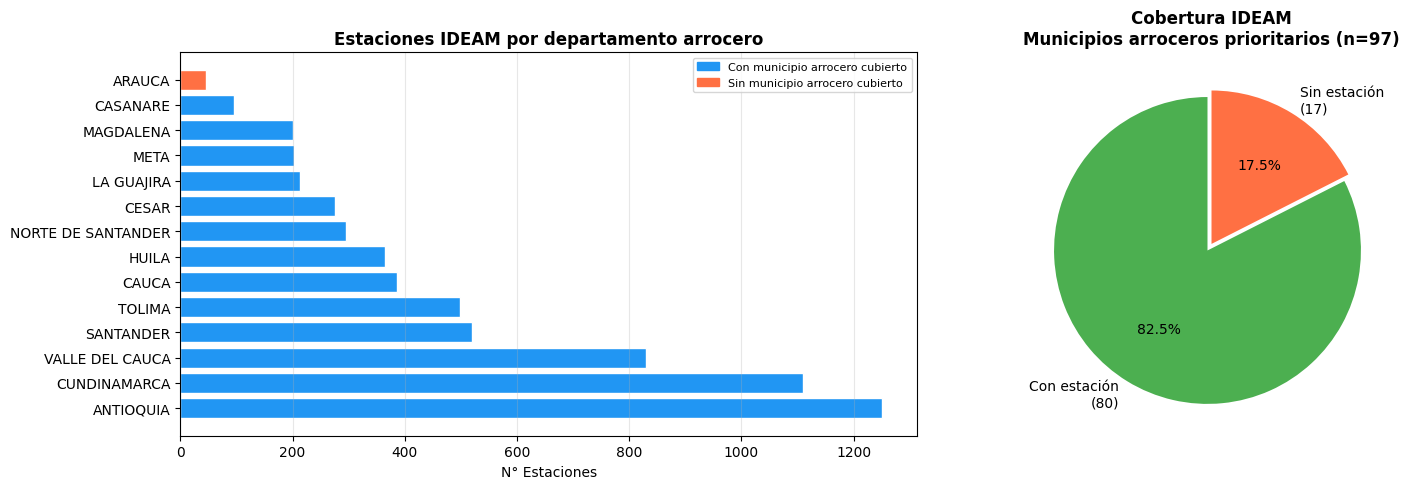

In [12]:
# ============================================================
# VISUALIZACIÓN 1 — Barras: N° estaciones por departamento arrocero
# ============================================================

# Estaciones IDEAM en los departamentos arroceros del proyecto
deptos_proyecto = df_municipios_arroz["Departamento"].unique()

df_est_deptos = (
    df_estaciones[
        df_estaciones["departamento"].isin(deptos_proyecto)
    ]
    .groupby("departamento", as_index=False)
    .size()
    .rename(columns={"departamento": "Departamento", "size": "N_Estaciones"})
    .sort_values("N_Estaciones", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ── Gráfica 1: Estaciones IDEAM en departamentos del proyecto ─
colores_barra = ["#2196F3" if d in set(df_con_estacion["Departamento"]) else "#FF7043"
                 for d in df_est_deptos["Departamento"]]

axes[0].barh(
    df_est_deptos["Departamento"],
    df_est_deptos["N_Estaciones"],
    color=colores_barra, edgecolor="white"
)
axes[0].set_title(
    "Estaciones IDEAM por departamento arrocero",
    fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("N° Estaciones")
axes[0].grid(axis="x", alpha=0.3)

parche_con = mpatches.Patch(color="#2196F3", label="Con municipio arrocero cubierto")
parche_sin = mpatches.Patch(color="#FF7043", label="Sin municipio arrocero cubierto")
axes[0].legend(handles=[parche_con, parche_sin], fontsize=8)

# ── Gráfica 2: Pastel de cobertura territorial ────────────────
labels_pie = [f"Con estación\n({n_con})", f"Sin estación\n({n_sin})"]
sizes_pie  = [n_con, n_sin]
colores_pie = ["#4CAF50", "#FF7043"]
explode     = (0.05, 0)

if n_sin == 0:
    axes[1].pie(
        [1], labels=[f"100% con estación ({n_con})"],
        colors=["#4CAF50"], autopct="%1.0f%%", startangle=90
    )
else:
    axes[1].pie(
        sizes_pie, labels=labels_pie, colors=colores_pie,
        autopct="%1.1f%%", explode=explode, startangle=90
    )
axes[1].set_title(
    f"Cobertura IDEAM\nMunicipios arroceros prioritarios (n={n_total})",
    fontsize=12, fontweight="bold"
)

plt.tight_layout()
plt.show()

---
## 🗺️ CELDA 13 — Visualización: Mapa de dispersión de estaciones (lat/lon)

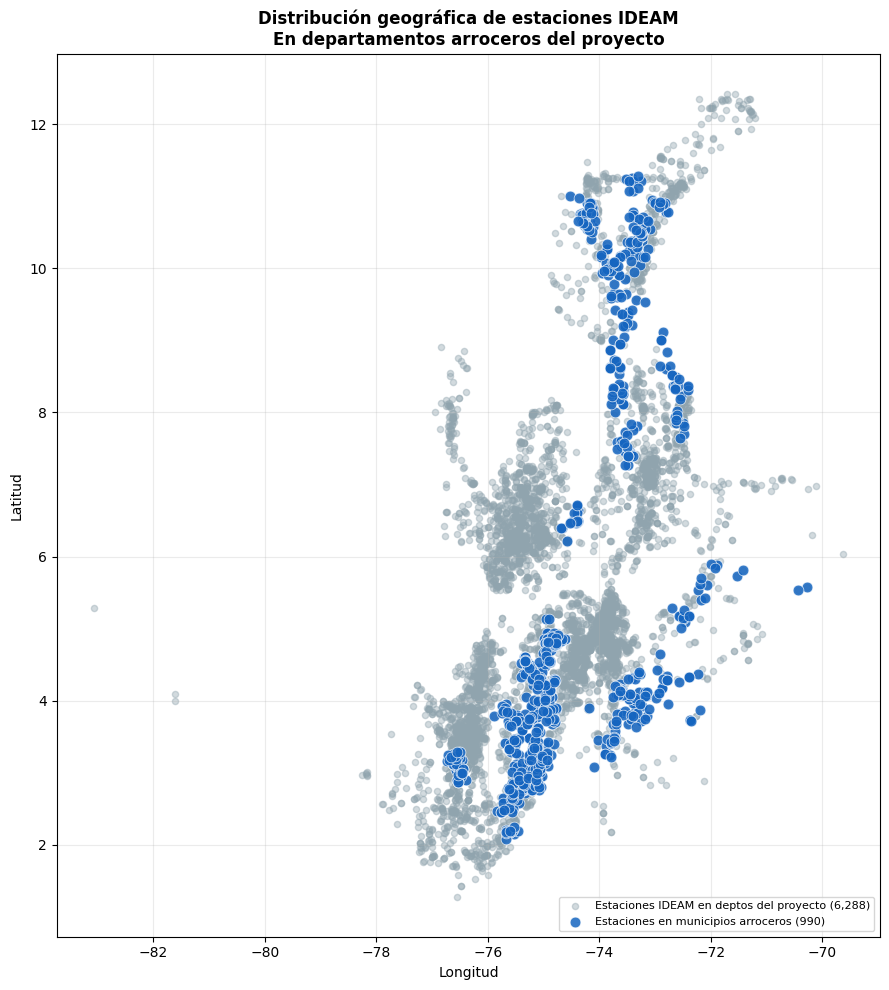


📍 Estaciones en departamentos del proyecto: 6,288
   De las cuales cubren municipios arroceros: 990


In [13]:
# ============================================================
# VISUALIZACIÓN 2 — Scatter geográfico: Estaciones vs Municipios arroceros
# ============================================================

# Estaciones con coordenadas válidas
df_geo = df_estaciones.dropna(subset=["latitud", "longitud"]).copy()

# Estaciones en departamentos del proyecto (para no saturar el mapa)
df_geo_proyecto = df_geo[
    df_geo["departamento"].isin(deptos_proyecto)
].copy()

fig, ax = plt.subplots(figsize=(9, 10))

# Todas las estaciones del proyecto (fondo gris)
ax.scatter(
    df_geo_proyecto["longitud"],
    df_geo_proyecto["latitud"],
    s=20, alpha=0.4, c="#90A4AE",
    label=f"Estaciones IDEAM en deptos del proyecto ({len(df_geo_proyecto):,})"
)

# Estaciones que cubren municipios arroceros con estación (azul)
if "key" in df_estaciones.columns:
    keys_con = set(df_con_estacion["key"])
    df_geo_arroz = df_geo[
        df_geo["key"].isin(keys_con)
    ].copy()
    ax.scatter(
        df_geo_arroz["longitud"],
        df_geo_arroz["latitud"],
        s=60, alpha=0.85, c="#1565C0",
        edgecolors="white", linewidths=0.5,
        label=f"Estaciones en municipios arroceros ({len(df_geo_arroz):,})",
        zorder=3
    )

ax.set_title(
    "Distribución geográfica de estaciones IDEAM\nEn departamentos arroceros del proyecto",
    fontsize=12, fontweight="bold"
)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.legend(loc="lower right", fontsize=8)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

print(f"\n📍 Estaciones en departamentos del proyecto: {len(df_geo_proyecto):,}")
print(f"   De las cuales cubren municipios arroceros: {len(df_geo_arroz):,}")

---
## 💾 CELDA 14 — Guardar análisis de cobertura territorial en `data/processed/`

In [14]:
# ============================================================
# GUARDAR — Cobertura territorial y lista de filtros
# Destino: data/processed/14_DF_Cobertura_Territorial.xlsx
# ============================================================

# Hoja 1: cobertura completa de municipios arroceros
df_cobertura_hoja1 = df_municipios_arroz[
    ["Departamento", "Municipio", "tiene_estacion"]
].copy()
df_cobertura_hoja1["tiene_estacion"] = df_cobertura_hoja1["tiene_estacion"].map(
    {True: "SÍ", False: "NO"}
)
df_cobertura_hoja1 = df_cobertura_hoja1.rename(
    columns={"tiene_estacion": "Tiene_Estacion_IDEAM"}
)

# Hoja 2: detalle del cruce con códigos de estación
df_cobertura_hoja2 = df_cruce_limpio.copy()

# Hoja 3: lista limpia de filtros para MOD-04, MOD-05 y MOD-06
df_filtros_export = df_filtros.copy()
df_filtros_export["tiene_estacion"] = df_filtros_export["tiene_estacion"].map(
    {True: "SÍ", False: "NO"}
)

guardar_excel(
    {
        "Cobertura_Municipios"   : df_cobertura_hoja1,
        "Detalle_Estaciones"     : df_cobertura_hoja2,
        "Filtros_MOD04_MOD05_MOD06"    : df_filtros_export
    },
    ARCHIVO_COBERTURA,
    nombre_log="14_DF_Cobertura_Territorial.xlsx"
)

✅ Guardado: 14_DF_Cobertura_Territorial.xlsx
   Ruta  : /content/drive/MyDrive/Colab Notebooks/Proyecto_Aplicado_II/data/processed/14_DF_Cobertura_Territorial.xlsx
   Hojas : ['Cobertura_Municipios', 'Detalle_Estaciones', 'Filtros_MOD04_MOD05_MOD06']
   Total : 1,184 filas



---
## ✅ CELDA 15 — Resumen de ejecución del módulo

In [15]:
# ============================================================
# RESUMEN FINAL — MOD-02 completado
# ============================================================

print("=" * 62)
print("  ✅ MOD-02 — Catálogo de Estaciones Climáticas COMPLETADO")
print("=" * 62)

print("\n📦 Archivos generados:")
archivos = [
    ("data/raw/",       "02_raw_Estaciones_IDEAM.json",
     "Respuesta original de la API"),
    ("data/processed/", "13_DF_Estaciones_Climaticas.xlsx",
     "Catálogo completo normalizado"),
    ("data/processed/", "14_DF_Cobertura_Territorial.xlsx",
     "Cobertura + Detalle + Filtros (3 hojas)"),
]
for carpeta, archivo, desc in archivos:
    print(f"   📄 {carpeta}{archivo}")
    print(f"      {desc}")

print("\n📊 DataFrames disponibles para módulos siguientes:")
print(f"   df_estaciones          → {df_estaciones.shape[0]:,} estaciones del catálogo IDEAM")
print(f"   df_municipios_arroz    → {len(df_municipios_arroz)} municipios arroceros")
print(f"   df_con_estacion        → {len(df_con_estacion)} municipios con cobertura confirmada")
print(f"   filtros                → {len(filtros)} pares (depto, municipio) para descarga")

print("\n🗺️  Cobertura territorial:")
print(f"   {n_con}/{n_total} municipios arroceros con estación IDEAM ({cobertura_pct:.1f}%)")

print("\n➡️  Siguiente módulo : MOD-04 — Descarga y Pivoteo de Temperatura")
print("    Variable clave  : filtros (lista de tuplas depto-municipio)")
print("    API destino     : datos.gov.co recurso sbwg-7ju4 (Temperatura)")
print("=" * 62)

  ✅ MOD-02 — Catálogo de Estaciones Climáticas COMPLETADO

📦 Archivos generados:
   📄 data/raw/02_raw_Estaciones_IDEAM.json
      Respuesta original de la API
   📄 data/processed/13_DF_Estaciones_Climaticas.xlsx
      Catálogo completo normalizado
   📄 data/processed/14_DF_Cobertura_Territorial.xlsx
      Cobertura + Detalle + Filtros (3 hojas)

📊 DataFrames disponibles para módulos siguientes:
   df_estaciones          → 9,358 estaciones del catálogo IDEAM
   df_municipios_arroz    → 97 municipios arroceros
   df_con_estacion        → 80 municipios con cobertura confirmada
   filtros                → 97 pares (depto, municipio) para descarga

🗺️  Cobertura territorial:
   80/97 municipios arroceros con estación IDEAM (82.5%)

➡️  Siguiente módulo : MOD-04 — Descarga y Pivoteo de Temperatura
    Variable clave  : filtros (lista de tuplas depto-municipio)
    API destino     : datos.gov.co recurso sbwg-7ju4 (Temperatura)
